# S&P 500 next-session direction prediction

At the close of trading session $t$, predict whether each stock's split-adjusted close is higher on the next market session. This notebook uses a shared classifier across tickers and evaluates whether sector-relative features improve out-of-time predictions.

## 1. Define the prediction task

One example is a `(symbol, date)` pair. The target is 1 when the next consecutive market session's close is higher and 0 otherwise. `target_date` and `next_return` are retained for validation and analysis but never used as model inputs.

In [1]:
from pathlib import Path
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

# Change only DATA_DIR when the CSVs live elsewhere.
DATA_DIR = Path("data")
PRICES_FILE = DATA_DIR / "prices-split-adjusted.csv"
SECURITIES_FILE = DATA_DIR / "securities.csv"
DATASET_SOURCE = "Kaggle dgawlik/nyse, version 3; downloaded 2026-11-16"

RETURN_WINDOWS = (1, 5, 20)
ROLLING_WINDOW = 20
TRAIN_END = pd.Timestamp("2014-12-31")
VALIDATION_START = pd.Timestamp("2015-01-01")
VALIDATION_END = pd.Timestamp("2015-12-31")
TEST_START = pd.Timestamp("2016-01-01")
TEST_END = pd.Timestamp("2016-12-31")
RANDOM_SEED = 363

pd.set_option("display.max_columns", 100)
print({
    "python": platform.python_version(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "scikit_learn": sklearn.__version__,
    "dataset": DATASET_SOURCE,
})

{'python': '3.12.3', 'pandas': '3.1.1', 'numpy': '2.5.5', 'scikit_learn': '1.9.1', 'dataset': 'Kaggle dgawlik/nyse, version 3; downloaded 2026-11-16'}


## 2. Load, clean, and explore the data

This section validates the raw schema, reports each cleaning decision, joins sector metadata, and inserts explicit missing rows on absent market sessions. It does not silently treat a ticker's next observed row as its next trading session.

In [2]:
def require_files(*paths):
    missing = [str(path) for path in paths if not path.exists()]
    if missing:
        raise FileNotFoundError(
            "Missing input file(s): " + ", ".join(missing)
            + ". See data/README.md for download instructions."
        )


def find_column(frame, candidates, purpose):
    lookup = {str(column).strip().lower(): column for column in frame.columns}
    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]
    raise ValueError(f"Could not find {purpose}; available columns: {list(frame.columns)}")


require_files(PRICES_FILE, SECURITIES_FILE)
prices_raw = pd.read_csv(PRICES_FILE)
securities_raw = pd.read_csv(SECURITIES_FILE)

print("Raw prices shape:", prices_raw.shape)
print("Raw securities shape:", securities_raw.shape)
display(prices_raw.head())
display(securities_raw.head())

Raw prices shape: (851264, 7)
Raw securities shape: (505, 8)


,date,symbol,open,close,low,high,volume
0,2016-01-05,WLTW,123.430000,125.839996,122.309998,126.250000,2163600.0
1,2016-01-06,WLTW,125.239998,119.980003,119.940002,125.540001,2386400.0
2,2016-01-07,WLTW,116.379997,114.949997,114.930000,119.739998,2489500.0
3,2016-01-08,WLTW,115.480003,116.620003,113.500000,117.440002,2006300.0
4,2016-01-11,WLTW,117.010002,114.970001,114.089996,117.330002,1408600.0


,Ticker symbol,Security,SEC filings,GICS Sector,GICS Sub Industry,Address of Headquarters,Date first added,CIK
0,MMM,3M Company,reports,Industrials,Industrial Conglomerates,"St. Paul, Minnesota",NaN,66740
1,ABT,Abbott Laboratories,reports,Health Care,Health Care Equipment,"North Chicago, Illinois",1964-03-31,1800
2,ABBV,AbbVie,reports,Health Care,Pharmaceuticals,"North Chicago, Illinois",2012-12-31,1551152
3,ACN,Accenture plc,reports,Information Technology,IT Consulting & Other Services,"Dublin, Ireland",2011-07-06,1467373
4,ATVI,Activision Blizzard,reports,Information Technology,Home Entertainment Software,"Santa Monica, California",2015-08-31,718877


In [3]:
def clean_prices(raw):
    expected = {"date", "symbol", "open", "high", "low", "close", "volume"}
    normalized = {str(column).strip().lower(): column for column in raw.columns}
    missing = expected - set(normalized)
    if missing:
        raise ValueError(f"Prices file is missing columns: {sorted(missing)}")

    frame = raw.rename(columns={normalized[name]: name for name in expected}).copy()
    summary = [{"step": "raw rows", "affected_rows": 0, "remaining_rows": len(frame)}]

    before = len(frame)
    frame = frame.drop_duplicates()
    summary.append({"step": "remove exact duplicates", "affected_rows": before - len(frame), "remaining_rows": len(frame)})

    frame["date"] = pd.to_datetime(frame["date"], errors="coerce")
    frame["symbol"] = frame["symbol"].astype("string").str.strip().str.upper()
    numeric_columns = ["open", "high", "low", "close", "volume"]
    frame[numeric_columns] = frame[numeric_columns].apply(pd.to_numeric, errors="coerce")

    duplicate_key = frame.duplicated(["symbol", "date"], keep=False)
    conflicting_rows = frame.loc[duplicate_key].sort_values(["symbol", "date"])
    if not conflicting_rows.empty:
        display(conflicting_rows.head(20))
        raise ValueError(
            f"Found {duplicate_key.sum():,} conflicting rows sharing (symbol, date). "
            "Inspect the displayed rows and define a documented resolution before continuing."
        )
    summary.append({"step": "conflicting (symbol, date) rows", "affected_rows": int(duplicate_key.sum()), "remaining_rows": len(frame)})

    invalid_key = frame["date"].isna() | frame["symbol"].isna() | frame["symbol"].eq("")
    invalid_close = frame["close"].isna() | frame["close"].le(0)
    invalid_volume = frame["volume"].isna() | frame["volume"].lt(0)
    inconsistent_ohlc = (
        frame[["open", "high", "low"]].isna().any(axis=1)
        | frame["high"].lt(frame[["open", "close", "low"]].max(axis=1))
        | frame["low"].gt(frame[["open", "close", "high"]].min(axis=1))
    )

    for name, mask in [
        ("invalid date or symbol", invalid_key),
        ("missing or nonpositive close", invalid_close),
        ("missing or negative volume", invalid_volume),
        ("missing or inconsistent OHLC range", inconsistent_ohlc),
    ]:
        summary.append({"step": name, "affected_rows": int(mask.sum()), "remaining_rows": None})

    invalid = invalid_key | invalid_close | invalid_volume | inconsistent_ohlc
    frame = frame.loc[~invalid].sort_values(["symbol", "date"]).reset_index(drop=True)
    summary.append({"step": "remove rows failing any validity check", "affected_rows": int(invalid.sum()), "remaining_rows": len(frame)})

    assert not frame.duplicated(["symbol", "date"]).any()
    return frame, pd.DataFrame(summary)


prices, cleaning_summary = clean_prices(prices_raw)
display(cleaning_summary)
print({
    "cleaned_rows": len(prices),
    "date_min": prices["date"].min(),
    "date_max": prices["date"].max(),
    "ticker_count": prices["symbol"].nunique(),
})

,step,affected_rows,remaining_rows
0,raw rows,0,851264.0
1,remove exact duplicates,0,851264.0
2,"conflicting (symbol, date) rows",0,851264.0
3,invalid date or symbol,0,NaN
4,missing or nonpositive close,0,NaN
5,missing or negative volume,0,NaN
6,missing or inconsistent OHLC range,0,NaN
7,remove rows failing any validity check,0,851264.0


{'cleaned_rows': 851264, 'date_min': Timestamp('2010-01-04 00:00:00'), 'date_max': Timestamp('2016-12-30 00:00:00'), 'ticker_count': 501}


In [4]:
ticker_column = find_column(securities_raw, ["Ticker symbol", "symbol", "ticker"], "security ticker column")
sector_column = find_column(securities_raw, ["GICS Sector", "sector"], "GICS sector column")

securities = (
    securities_raw[[ticker_column, sector_column]]
    .rename(columns={ticker_column: "symbol", sector_column: "sector"})
    .assign(
        symbol=lambda x: x["symbol"].astype("string").str.strip().str.upper(),
        sector=lambda x: x["sector"].astype("string").str.strip(),
    )
    .drop_duplicates()
)
if securities["symbol"].duplicated().any():
    display(securities.loc[securities["symbol"].duplicated(keep=False)].sort_values("symbol"))
    raise ValueError("Sector metadata has multiple mappings for at least one ticker.")

prices = prices.merge(securities, on="symbol", how="left", validate="many_to_one")
unmatched = prices["sector"].isna()
print({
    "unmatched_tickers": prices.loc[unmatched, "symbol"].nunique(),
    "unmatched_rows": int(unmatched.sum()),
})

{'unmatched_tickers': 0, 'unmatched_rows': 0}


In [5]:
# The full input panel defines the market-session calendar. Reindex each ticker
# so a missing observation remains explicit and cannot become a one-session return.
sessions = pd.Index(np.sort(prices["date"].unique()), name="date")
symbols = pd.Index(np.sort(prices["symbol"].unique()), name="symbol")
full_index = pd.MultiIndex.from_product([symbols, sessions], names=["symbol", "date"])

panel = (
    prices.set_index(["symbol", "date"])
    .reindex(full_index)
    .reset_index()
)
panel["sector"] = panel.groupby("symbol", sort=False)["sector"].transform(lambda x: x.ffill().bfill())
panel["session_number"] = panel["date"].map(pd.Series(np.arange(len(sessions)), index=sessions))

assert not panel.duplicated(["symbol", "date"]).any()
print({
    "market_sessions": len(sessions),
    "panel_rows": len(panel),
    "observed_price_rows": int(panel["close"].notna().sum()),
    "explicit_missing_rows": int(panel["close"].isna().sum()),
})

{'market_sessions': 1762, 'panel_rows': 882762, 'observed_price_rows': 851264, 'explicit_missing_rows': 31498}


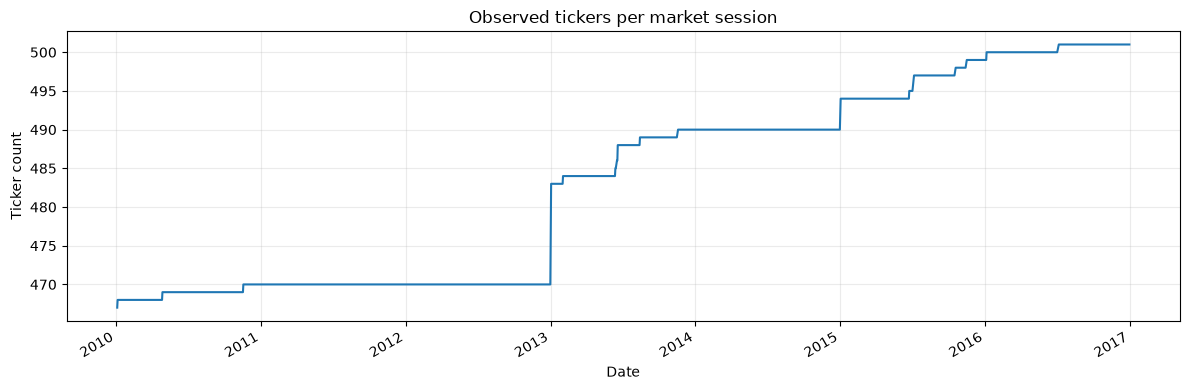

,missing_fraction
open,0.04772
high,0.04772
low,0.04772
close,0.04772
volume,0.04772
sector,0.00000


In [6]:
coverage = panel.groupby("date")["close"].count()
fig, ax = plt.subplots(figsize=(12, 4))
coverage.plot(ax=ax)
ax.set(title="Observed tickers per market session", xlabel="Date", ylabel="Ticker count")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

training_panel = panel.loc[panel["date"].le(TRAIN_END)]
training_missingness = (
    training_panel[["open", "high", "low", "close", "volume", "sector"]]
    .isna().mean().rename("missing_fraction").to_frame()
)
display(training_missingness)

### Cleaning observation

All 851,264 raw price rows passed the key, price, volume, and OHLC validity checks, and all 501 tickers matched sector metadata. The important data issue is incomplete panel coverage: aligning 501 tickers to 1,762 market sessions exposes 31,498 missing stock-session observations. These rows remain missing, preventing a ticker's next observed price after a gap from being mislabeled as the next-session price.

## 3. Engineer and test the features

Next implementation milestone: construct consecutive-session labels and trailing stock features on `panel`, then add the sector-relative feature experiment and leakage tests.